In [ ]:
# 당뇨병 환자 데이터셋
from sklearn.datasets import load_diabetes
from sklearn.model_selection import cross_val_score

In [ ]:
# 신체 검사 수치들을 바탕으로 1년 뒤 질병의 진행 정도를 예측하는 회귀 데이터셋
X, y = load_diabetes(return_X_y=True)
print(f'X = {X.shape}')
print(f'y = {y.shape}')
# 데이터를 총 5조각(n_splits=5)으로 나누고, 무작위로 섞는(shuffle=True) K-Fold 교차검증 객체
cv = KFold(n_splits=5, shuffle=True, random_state=0)

X = (442, 10)
y=(442,)


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression

models = {'Linear': LinearRegression(),
          'RandomForest': RandomForestRegressor(n_estimators=200, random_state=0),
          'XGBoost': XGBRegressor(n_estimators=200, max_depth=3, random_state=0)}

for name, model in models.items():
    # 모델별로 k-Fold 교차검증 하고 R2 성능 측정
    s = cross_val_score(model, X, y, cv=cv, scoring='r2')
    # R2 점수 평균(s.mean())과 표준편차(s.std())
    print(f'{name:12s} R2 = {s.mean():.3f} ± {s.std():.3f}')

Linear       R2 = 0.489 ± 0.090
RandomForest R2 = 0.427 ± 0.098
XGBoost      R2 = 0.321 ± 0.167


--- Target과의 상관계수 ---
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


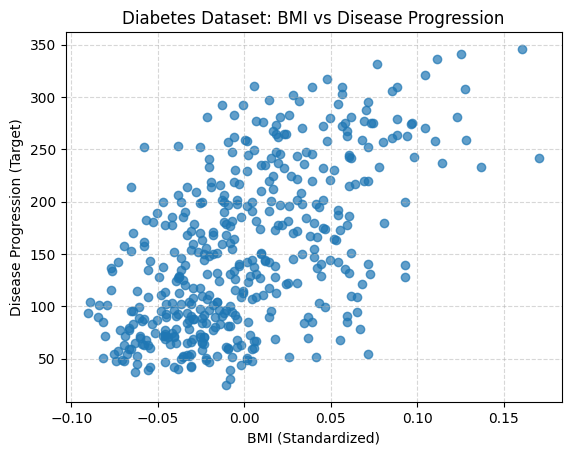

In [13]:
# 왜 Linear 의 R2 가 높게 나온지 데이터를 확인해 보자
import matplotlib.pyplot as plt
# 1. 데이터 로드 - frame 형태로
X, y = load_diabetes(return_X_y=True, as_frame=True)

# 2. 전체 피처와 타겟 간의 상관계수 확인
X['target'] = y
correlation = X.corr()['target'].sort_values(ascending=False)
print("--- Target과의 상관계수 ---")
print(correlation)


# 3. BMI(두 번째 컬럼 'bmi')와 타겟(y) 관계 시각화
plt.scatter(X['bmi'], y, alpha=0.7)
plt.title('Diabetes Dataset: BMI vs Disease Progression', fontsize=12)
plt.xlabel('BMI (Standardized)', fontsize=10)
plt.ylabel('Disease Progression (Target)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

